In [41]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
import smarts_cerebellum.globals as gl

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_Nettekoven_2024_FaMap.tsv'), sep = '\t')
lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_Nettekoven_2024_lme.tsv'), sep = '\t')
lme['region_bilat'] = lme['regionname'].astype(str).str[-1]

m_rois = []
a_rois = []
d_rois = []
s_rois = []

for roi in gl.rois['Nettekoven2024']:
    if roi[0] == 'M':
        m_rois.append(roi)
    elif roi[0] == 'A':
        a_rois.append(roi)
    elif roi[0] == 'D':
        d_rois.append(roi)
    elif roi[0] == 'S':
        s_rois.append(roi)
    else:
        print('na')

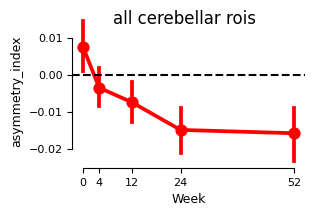

In [42]:
fig, ax = plt.subplots(figsize = (3,2))
sns.pointplot(x = 'Week', y = 'asymmetry_index', data = obs[obs.hemisphere == 'L'], native_scale = True, ax = ax, color = 'red')

ax.set_xticks(gl.weeks)
ax.axhline(y = 0, linestyle = '--', color = 'k')

fig.suptitle("all cerebellar rois", y = .9)
sns.despine(trim = True)
plt.show()

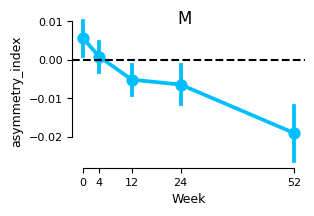

0 1.239175115105794 0.21914454472287012
4 0.2128348968981399 0.8319318023415493
12 -1.3096587294060804 0.19334243318541153
24 -1.275168635458432 0.2056443181969748
52 -2.659836108005867 0.011285729271544453


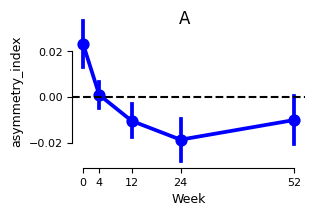

0 2.3272260166768786 0.023593991246434683
4 0.17437669446370932 0.862087554257862
12 -1.4330456934160203 0.15605619876402832
24 -2.020576534761461 0.047447429321684075
52 -0.9562286164761815 0.3468607659110078


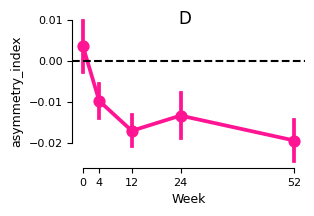

0 0.5611883149537698 0.5763421232284204
4 -2.40126594745766 0.018372369956153347
12 -4.473642520031567 2.0555079324161032e-05
24 -2.438277983652757 0.01679092825941089
52 -3.9452478130905972 0.00032245030118549533


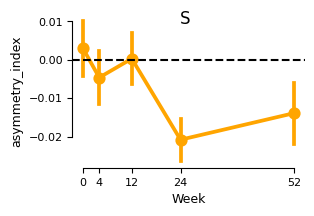

0 0.41059348242195964 0.6823050729201157
4 -0.6634932174028365 0.5083542435200086
12 0.0424982065345243 0.9661698975768489
24 -3.8093285534847583 0.00023088919837834388
52 -1.7522360568794415 0.08598926097970676


In [43]:
colours = ['deepskyblue', 'blue', 'deeppink', 'orange']
for r, region in enumerate(['M', 'A', 'D', 'S']):
    fig, ax = plt.subplots(figsize = (3,2), sharey = True, sharex = True)

    obs_roi = obs[(obs.regionname.str.contains(region))&(obs.hemisphere == 'L')]
    sns.pointplot(x='Week', y = 'asymmetry_index', data = obs_roi, native_scale = True, ax = ax, color = colours[r], errorbar = 'se')

    ax.set_xticks(gl.weeks)
    ax.axhline(y = 0, linestyle = '--', color = 'k')
    fig.suptitle(region, y = .9)
    sns.despine(trim = True)
    plt.show()
    for week in gl.weeks:
        r, p = stats.ttest_1samp(obs_roi[obs_roi.Week == week]['asymmetry_index'], popmean = 0)
        print(week,r, p)

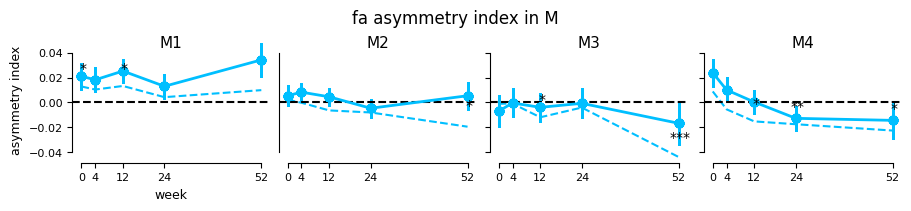

In [44]:
fig, axs = plt.subplots(1, len(m_rois), figsize=(9, 2), sharey = True, sharex = True, constrained_layout = True)

for r, m_roi in enumerate(m_rois):
    lme_m_roi = lme[lme.regionname.str.contains(m_roi)].sort_values('Week')
    obs_m_roi = obs[obs.regionname.str.contains(m_roi)].sort_values('Week')

    obs_m_mean = obs_m_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_m_roi['Week'], y=lme_m_roi['beta'], yerr = lme_m_roi['se'], fmt = '-o',  linewidth = 2, color = 'deepskyblue')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'deepskyblue')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_m_roi.loc[obs_m_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_xticks(gl.weeks)
    ax.set_title(m_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('asymmetry index')
axs[0].set_xlabel('week')

fig.suptitle(f'fa asymmetry index in M')
sns.despine(trim = True)


plt.show()


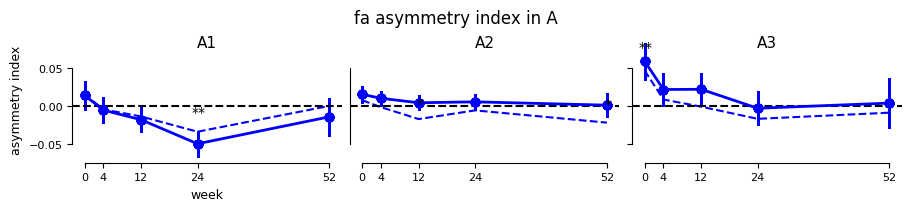

In [45]:
fig, axs = plt.subplots(1, len(a_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, a_roi in enumerate(a_rois):
    lme_a_roi = lme[lme.regionname.str.contains(a_roi)].sort_values('Week')
    obs_a_roi = obs[obs.regionname.str.contains(a_roi)].sort_values('Week')

    obs_m_mean = obs_a_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_a_roi['Week'], y=lme_a_roi['beta'], yerr = lme_a_roi['se'], fmt = '-o',  linewidth = 2, color = 'blue')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'blue')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_a_roi.loc[obs_a_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_xticks(gl.weeks)
    ax.set_title(a_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('asymmetry index')
axs[0].set_xlabel('week')


fig.suptitle(f'fa asymmetry index in A')
sns.despine(trim = True)


plt.show()


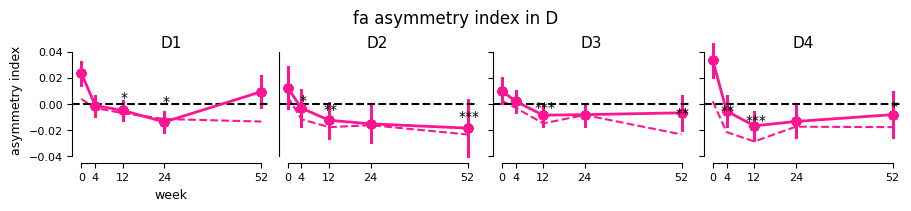

In [46]:
fig, axs = plt.subplots(1, len(d_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, d_roi in enumerate(d_rois):
    lme_d_roi = lme[lme.regionname.str.contains(d_roi)].sort_values('Week')
    obs_d_roi = obs[obs.regionname.str.contains(d_roi)].sort_values('Week')

    obs_m_mean = obs_d_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_d_roi['Week'], y=lme_d_roi['beta'], yerr = lme_d_roi['se'], fmt = '-o',  linewidth = 2, color = 'deeppink')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'deeppink')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_d_roi.loc[obs_d_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_xticks(gl.weeks)
    ax.set_title(d_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('asymmetry index')
axs[0].set_xlabel('week')

fig.suptitle(f'fa asymmetry index in D')
sns.despine(trim = True)


plt.show()


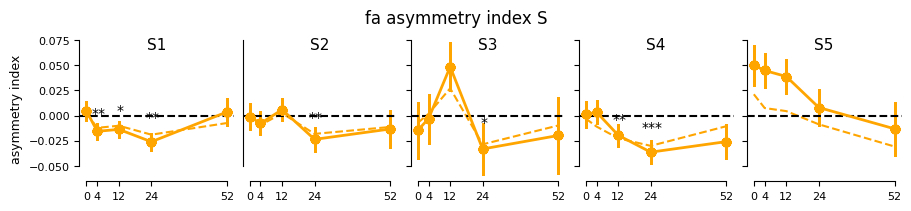

In [47]:
fig, axs = plt.subplots(1, len(s_rois), figsize=(9, 2), sharey = True, constrained_layout = True)

for r, s_roi in enumerate(s_rois):
    lme_s_roi = lme[lme.regionname.str.contains(s_roi)].sort_values('Week')
    obs_s_roi = obs[obs.regionname.str.contains(s_roi)].sort_values('Week')

    obs_m_mean = obs_s_roi.groupby('Week', as_index = False)['asymmetry_index'].mean()
    
    ax = axs[r]
    ax.errorbar(x=lme_s_roi['Week'], y=lme_s_roi['beta'], yerr = lme_s_roi['se'], fmt = '-o',  linewidth = 2, color = 'orange')
    ax.plot(obs_m_mean['Week'], obs_m_mean['asymmetry_index'], linestyle = '--', color = 'orange')

    # annotate for significance
    for week in gl.weeks:
        vals = obs_s_roi.loc[obs_s_roi.Week == week, 'asymmetry_index']
        mean, sem = vals.mean(), vals.sem()

        p = stats.ttest_1samp(vals, 0).pvalue
        stars = '***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''
        if stars:
            ax.annotate(stars, xy = (week, mean + sem), xytext = (1, 5), textcoords = 'offset points', ha = 'center')

    ax.axhline(y=0, color = 'black', linestyle = '--')
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_xticks(gl.weeks)
    ax.set_title(s_roi, y = .85)


axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('asymmetry index')

fig.suptitle(f'fa asymmetry index S')
sns.despine(trim = True)


plt.show()
